# Used Cars Market Analysis Project

## Project Overview:
This project explores a dataset of used-car listings in Saudi Arabia. It aims to prepare the data for analysis, identify and address data-quality issues, and summarize key patterns in the used-car market.
    
## Project Objectives:
- Inspect the dataset and identify missing, invalid, or unusual values.
- Clean the price and mileage columns and remove duplicate records.
- Save the cleaned dataset for further use.
- Analyze listings and median prices by car manufacturer, manufacturing year, and region.
- Create charts to present the main findings.
- Generate an Excel market report and a reusable Python report-generation script.
                                                        
## Tools and Libraries
The project uses Python, Pandas, Matplotlib, and OpenPyXL for data processing, analysis, visualization, and Excel report generation.
                                                        
## Expected Outcome
The final outputs include a cleaned CSV dataset, visual summaries, and Excel reports that help describe the used-car listings and price patterns in the dataset.

### Install the libraries required for the project: `pandas` for data processing, `matplotlib` for charts, and `openpyxl` for creating Excel files.

In [1]:
pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


### Import the Pandas library and use the alias `pd` to make reading, cleaning, and analyzing the data easier.

In [2]:
import pandas as pd

### Read the uncleaned car dataset from a CSV file and store it in a DataFrame named `df`.

In [3]:
df = pd.read_csv("UsedCarsSA_Unclean_EN.csv")

### Display the first five rows to become familiar with the column names and the structure of the records.

In [4]:
df.head()

,Link,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Condition,Mileage,Region,Price,Negotiable
0,https://syarah.com/%D9%83%D8%B1%D8%A7%D9%8A%D8...,Chrysler,C300,2018,Saudi,Black,Full,5.7,Gas,Automatic,Used,103000,Riyadh,114000,False
1,https://syarah.com/%D9%86%D9%8A%D8%B3%D8%A7%D9...,Nissan,Patrol,2016,Saudi,White,Full,4.8,Gas,Automatic,Used,5448,Riyadh,Negotiable,True
2,https://syarah.com/online/%D9%86%D9%8A%D8%B3%D...,Nissan,Sunny,2019,Saudi,Silver,Standard,1.5,Gas,Automatic,Used,72418,Riyadh,27500,False
3,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Grey,Standard,1.6,Gas,Automatic,Used,114154,Riyadh,43000,False
4,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Silver,Semi Full,2.0,Gas,Automatic,Used,41912,Riyadh,59500,False


### Inspect the DataFrame information, including column data types, the number of non-missing values, and the dataset size.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8248 entries, 0 to 8247
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Link         8248 non-null   object 
 1   Make         8248 non-null   object 
 2   Type         8248 non-null   object 
 3   Year         8248 non-null   int64  
 4   Origin       8153 non-null   object 
 5   Color        8248 non-null   object 
 6   Options      8139 non-null   object 
 7   Engine_Size  5982 non-null   float64
 8   Fuel_Type    8248 non-null   object 
 9   Gear_Type    8174 non-null   object 
 10  Condition    8248 non-null   object 
 11  Mileage      8248 non-null   int64  
 12  Region       8248 non-null   object 
 13  Price        8248 non-null   object 
 14  Negotiable   8248 non-null   bool   
dtypes: bool(1), float64(1), int64(2), object(11)
memory usage: 910.3+ KB


### Identify the data quality issues addressed in this project: missing values in some columns and an incorrect data type in the price column.

### Begin cleaning the price column by inspecting its values and converting them into a numeric format suitable for analysis.

In [6]:
df["Price"].head(10)

0        114000
1    Negotiable
2         27500
3         43000
4         59500
5         72000
6         92000
7    Negotiable
8         80000
9         32000
Name: Price, dtype: object

### Remove thousands separators from the price values and attempt to convert them to numbers. Values that cannot be converted become missing, after which the most frequent invalid values are displayed.

In [7]:
price_clean = pd.to_numeric(df["Price"].astype(str).str.replace(",", ""), errors="coerce")
bad = df[price_clean.isna() & df["Price"].notna()]
print(bad["Price"].value_counts().head(10))
df["Price"] = price_clean

Price
Negotiable    2596
Name: count, dtype: int64


### Display the DataFrame after converting the price column to review the updated data and its resulting values.

In [8]:
df

,Link,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Condition,Mileage,Region,Price,Negotiable
0,https://syarah.com/%D9%83%D8%B1%D8%A7%D9%8A%D8...,Chrysler,C300,2018,Saudi,Black,Full,5.7,Gas,Automatic,Used,103000,Riyadh,114000.0,False
1,https://syarah.com/%D9%86%D9%8A%D8%B3%D8%A7%D9...,Nissan,Patrol,2016,Saudi,White,Full,4.8,Gas,Automatic,Used,5448,Riyadh,NaN,True
2,https://syarah.com/online/%D9%86%D9%8A%D8%B3%D...,Nissan,Sunny,2019,Saudi,Silver,Standard,1.5,Gas,Automatic,Used,72418,Riyadh,27500.0,False
3,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Grey,Standard,1.6,Gas,Automatic,Used,114154,Riyadh,43000.0,False
4,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Silver,Semi Full,2.0,Gas,Automatic,Used,41912,Riyadh,59500.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8243,https://syarah.com/%D9%84%D9%84%D8%A8%D9%8A%D8...,Audi,A6,2015,Saudi,Silver,Full,NaN,Gas,Automatic,Used,77000,Riyadh,75000.0,False
8244,https://syarah.com/%D9%84%D9%84%D8%A8%D9%8A%D8...,Chevrolet,Camaro,2010,Saudi,Silver,Full,NaN,Gas,Automatic,Used,150000,Riyadh,53000.0,False
8245,https://syarah.com/%D8%AA%D9%88%D9%8A%D9%88%D8...,Toyota,Land Cruiser,2013,Gulf Arabic,White,Full,NaN,Gas,Automatic,Used,260,Najran,NaN,True
8246,https://syarah.com/%D9%86%D9%8A%D8%B3%D8%A7%D9...,Nissan,Altima,2011,Saudi,Silver,Full,2.5,Gas,Automatic,Used,18500,Aseer,22000.0,False


### Check the number of missing prices, the column data type, and the number of zero prices, then display descriptive statistics for price.

In [9]:
print(df["Price"].isna().sum())     # المتوقع 2596
print(df["Price"].dtype)          # المتوقع float64
print((df["Price"] == 0).sum())     # كم سعر صفر؟
print(df["Price"].describe())       # أقل وأعلى سعر

2596
float64
1
count    5.652000e+03
mean     7.853659e+04
std      7.607374e+04
min      0.000000e+00
25%      3.500000e+04
50%      5.800000e+04
75%      9.500000e+04
max      1.150000e+06
Name: Price, dtype: float64


### Treat a zero price as invalid for the analysis and replace it with a missing value rather than considering it a real price.

In [10]:
# 1. استبعاد السعر الصفري (نحوله NaN عشان ما يدخل التحليل)
df.loc[df["Price"] == 0, "Price"] = pd.NA

### Inspect the ten highest prices alongside their car details to visually check whether the high values appear reasonable.

In [11]:
# 2. فحص أعلى 10 أسعار لنتأكد أنها منطقية
df.nlargest(10, "Price")[["Make", "Type", "Year", "Mileage", "Price"]]

,Make,Type,Year,Mileage,Price
1049,Mercedes,G,2021,5000,1150000.0
6070,Bentley,Bentayga,2019,13000,850000.0
3934,Mercedes,G,2019,60000,835000.0
4151,Mercedes,G,2019,39000,800000.0
3276,Bentley,Arnage,2020,300,772500.0
923,Bentley,Bentayga,2018,26000,750000.0
6868,Bentley,Bentayga,2018,20000,750000.0
3497,Mercedes,S,2021,2500,748000.0
4628,Land Rover,Range Rover,2020,100,700000.0
6526,Rolls-Royce,Ghost,2013,24000,700000.0


### Compare missing-price status with whether the price is negotiable by using a crosstab to understand the relationship between them.

In [12]:
# 3. فحص الجدول المتقاطع مع Negotiable
print(pd.crosstab(df["Negotiable"], df["Price"].isna()))

Price       False  True 
Negotiable              
False        5651      1
True            0   2596


### Review descriptive statistics for mileage to understand its range and distribution.

In [13]:
df["Mileage"].describe()

count    8.248000e+03
mean     1.494128e+05
std      3.455258e+05
min      1.000000e+02
25%      3.700000e+04
50%      1.016575e+05
75%      1.955520e+05
max      2.000000e+07
Name: Mileage, dtype: float64

### Count the cars with mileage exceeding one million kilometers to identify potential outliers.

In [14]:
# كم سيارة مسافتها فوق مليون؟
print((df["Mileage"] > 1_000_000).sum())

45


### Display the fifteen highest mileage values with car details to inspect records with unusually high mileage.

In [15]:
# عرض أعلى 15 مسافة
df.nlargest(15, "Mileage")[["Make", "Type", "Year", "Mileage", "Price"]]

,Make,Type,Year,Mileage,Price
7590,Chevrolet,Optra,2009,20000000,9000.0
4595,Mercedes,POS24,1983,9999999,NaN
5202,Toyota,Aurion,2010,4900000,NaN
4797,Chevrolet,Tahoe,2012,4691232,NaN
7728,Toyota,Camry,1998,4500000,15000.0
6789,Toyota,Camry,2008,4430000,17500.0
7462,GMC,C5700,1977,4358765,NaN
1606,Nissan,Pathfinder,2002,4090000,NaN
3503,GMC,Suburban,2005,4010000,NaN
5689,Toyota,Land Cruiser,2006,4000000,NaN


### Use upper mileage percentiles (90%, 95%, 99%, and 99.9%) to understand the distribution's upper tail and identify unusual values.

In [16]:
# توزيع أدق: النسب المئوية العليا
df["Mileage"].quantile([0.90, 0.95, 0.99, 0.999])

0.900     300000.0
0.950     378000.0
0.990     600000.0
0.999    4007530.0
Name: Mileage, dtype: float64

### Replace mileage values exceeding one million kilometers with missing values, treating them as unreasonable under the cleaning rule used, then review the statistics after processing.

In [17]:
df.loc[df["Mileage"] > 1_000_000, "Mileage"] = pd.NA

print(df["Mileage"].isna().sum())   # المتوقع 45
df["Mileage"].describe()

45


count       8203.000000
mean      131613.501890
std       123026.282119
min          100.000000
25%        36100.000000
50%       101000.000000
75%       193132.500000
max      1000000.000000
Name: Mileage, dtype: float64

### Create a car-age column using 2026 as the reference year, then identify older cars with mileage below 1,000 to investigate whether their mileage may have been recorded using an incomplete unit or format.

In [18]:
REFERENCE_YEAR = 2026   # افتراض: غيّره إذا عرفت تاريخ جمع البيانات
df["Age"] = REFERENCE_YEAR - df["Year"]

mask = (df["Mileage"] < 1000) & (df["Age"] > 5)
suspicious = df[mask]
print(len(suspicious))

# توزيع القيم عشان نعرف هل هي "بالآلاف" أو أخطاء
print(suspicious["Mileage"].describe())
print(suspicious["Mileage"].value_counts().head(15))

suspicious[["Make", "Type", "Year", "Mileage"]].head(10)

913
count    913.000000
mean     255.406353
std      122.990819
min      100.000000
25%      170.000000
50%      230.000000
75%      300.000000
max      942.000000
Name: Mileage, dtype: float64
Mileage
300.0    68
100.0    37
200.0    31
400.0    31
280.0    18
500.0    15
130.0    14
180.0    13
170.0    12
350.0    12
260.0    12
220.0    11
290.0    11
150.0    10
160.0    10
Name: count, dtype: int64


,Make,Type,Year,Mileage
31,Toyota,Aurion,2015,300.0
42,Toyota,Land Cruiser,1993,400.0
114,Toyota,Land Cruiser,2015,242.0
210,Ford,Marquis,2010,290.0
263,GMC,Yukon,2011,200.0
381,Ford,Taurus,2015,199.0
548,Renault,Fluence,2015,280.0
574,Toyota,Camry,2009,317.0
599,Toyota,Camry,2010,145.0
623,Lexus,LX,2015,299.0


### Adjust the suspicious mileage values by multiplying them by 1,000. Add a Boolean column to flag the rows that were adjusted, then check the number of affected records and missing values.

In [19]:
mask = (df["Mileage"] < 1000) & (df["Age"] > 5)
df["Mileage_adjusted"] = mask          # علامة توضح أي الصفوف تم تعديلها
df.loc[mask, "Mileage"] = df.loc[mask, "Mileage"] * 1000

print(mask.sum())                      # المتوقع 913
print(df["Mileage"].isna().sum())      # المتوقع 45 فقط
df["Mileage"].describe()

913
45


count       8203.000000
mean      160011.991954
std       125682.149471
min          100.000000
25%        70000.000000
50%       130000.000000
75%       223000.000000
max      1000000.000000
Name: Mileage, dtype: float64

### Check the minimum and maximum manufacturing years in the dataset to understand the time range covered by the cars.

In [20]:
# 1. السنوات
print(df["Year"].min(), df["Year"].max())

1936 2022


### Count duplicate rows and remove exact duplicates. Print the row counts before and after removal, as well as the number of rows deleted.

In [21]:
# 2. الصفوف المكررة
print(df.duplicated().sum())
# 1) حذف المكرر الحقيقي (والرابط ما زال موجودًا)
before = len(df)
df = df.drop_duplicates()
print(before, len(df), before - len(df))   # المتوقع: 8248 8228 20

20
8248 8228 20


### Remove the `Link` column after it is no longer needed, then display the DataFrame dimensions to confirm the updated number of columns.

In [22]:
# 2) بعدها نحذف عمود الرابط
df = df.drop(columns=["Link"])
df.shape

(8228, 16)

### Prepare a final summary of the number of missing values in each column after the cleaning operations.

In [23]:
# 4. ملخص نهائي للقيم المفقودة
print(df.isna().sum())

Make                   0
Type                   0
Year                   0
Origin                95
Color                  0
Options              109
Engine_Size         2263
Fuel_Type              0
Gear_Type             74
Condition              0
Mileage               45
Region                 0
Price               2593
Negotiable             0
Age                    0
Mileage_adjusted       0
dtype: int64


### Inspect cars manufactured before 1990 and display the ten oldest records, sorted by year, to review whether they are suitable for the analysis.

In [24]:
print((df["Year"] < 1990).sum())
df[df["Year"] < 1990][["Make", "Type", "Year", "Mileage", "Price"]].sort_values("Year").head(10)

65


,Make,Type,Year,Mileage,Price
2843,Classic,Jaguar,1936,4750.0,NaN
7968,Buick,Riviera,1961,100000.0,NaN
4238,Ford,Other,1963,300000.0,22000.0
4092,Chevrolet,Impala,1964,100000.0,75000.0
5013,Ford,Thunderbird,1965,25000.0,NaN
7149,Cadillac,Eldorado,1968,91000.0,130000.0
5847,Mercedes,POS24,1970,300000.0,45000.0
5506,Classic,Mini Cooper,1972,1000.0,42000.0
6796,Mercedes,POS24,1975,22552.0,NaN
7462,GMC,C5700,1977,NaN,NaN


### Check again for any remaining duplicate rows and display examples after cleaning, sorting by the main car-detail columns.

In [25]:
dups = df[df.duplicated(keep=False)].sort_values(["Make", "Type", "Year", "Mileage"])
dups.head(10)

,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Condition,Mileage,Region,Price,Negotiable,Age,Mileage_adjusted
2085,Chevrolet,Camaro,2017,Other,Silver,Full,3.6,Gas,Automatic,Used,99000.0,Dammam,109000.0,False,9,False
2604,Chevrolet,Camaro,2017,Other,Silver,Full,3.6,Gas,Automatic,Used,99000.0,Dammam,109000.0,False,9,False
2092,Chevrolet,Silverado,2018,Saudi,White,Standard,5.3,Gas,Automatic,Used,57000.0,Dammam,89000.0,False,8,False
2899,Chevrolet,Silverado,2018,Saudi,White,Standard,5.3,Gas,Automatic,Used,57000.0,Dammam,89000.0,False,8,False
1820,Chevrolet,Silverado,2019,Saudi,White,Full,5.3,Gas,Automatic,Used,33000.0,Tabouk,170000.0,False,7,False
1821,Chevrolet,Silverado,2019,Saudi,White,Full,5.3,Gas,Automatic,Used,33000.0,Tabouk,170000.0,False,7,False
1822,Chevrolet,Silverado,2019,Saudi,White,Full,5.3,Gas,Automatic,Used,33000.0,Tabouk,170000.0,False,7,False
4984,Chevrolet,Tahoe,2001,Other,Grey,Full,2.7,Gas,Automatic,Used,260000.0,Qassim,NaN,True,25,False
5200,Chevrolet,Tahoe,2001,Other,Grey,Full,2.7,Gas,Automatic,Used,260000.0,Qassim,NaN,True,25,False
814,Chevrolet,Tahoe,2008,Saudi,Black,Semi Full,5.7,Gas,Automatic,Used,NaN,Riyadh,27000.0,False,18,False


### Save the cleaned dataset to a new CSV file named `used_cars_clean.csv`, without including the row index.

In [26]:
df.to_csv("used_cars_clean.csv", index=False)

### Group the data by manufacturer, calculate the number of listings and median price for each manufacturer, then display the ten manufacturers with the most listings.

In [27]:
top = (df.groupby("Make")
         .agg(listings=("Make", "size"),
              median_price=("Price", "median"))
         .sort_values("listings", ascending=False)
         .head(10))
top

,listings,median_price
Make,,
Toyota,2067,65000.0
Hyundai,950,42000.0
Ford,778,55000.0
Chevrolet,667,59250.0
Nissan,552,36500.0
GMC,411,72000.0
Kia,359,40000.0
Mercedes,349,145000.0
Lexus,345,142000.0


### Keep only cars manufactured in 2000 or later, then calculate the number of cars with recorded prices and the median price for each manufacturing year.

In [28]:
modern = df[df["Year"] >= 2000]
by_year = (modern.groupby("Year")
                 .agg(priced=("Price", "count"),
                      median_price=("Price", "median")))
by_year.tail(15)

,priced,median_price
Year,,
2008,107,27000.0
2009,104,32000.0
2010,132,30000.0
2011,164,36000.0
2012,192,41500.0
2013,319,50000.0
2014,348,52000.0
2015,585,65000.0
2016,886,68000.0


### Group listings by region and calculate the number of listings, the number of available prices, and the median price, then sort the regions by listing count.

In [29]:
by_region = (df.groupby("Region")
               .agg(listings=("Region", "size"),
                    priced=("Price", "count"),
                    median_price=("Price", "median"))
               .sort_values("listings", ascending=False))
by_region

,listings,priced,median_price
Region,,,
Riyadh,3300,2350,60000.0
Dammam,1404,1147,69000.0
Jeddah,1075,799,55000.0
Qassim,316,162,60000.0
Al-Medina,304,176,45000.0
Makkah,240,145,40000.0
Aseer,237,132,55000.0
Al-Ahsa,236,159,51000.0
Taef,140,70,37500.0


### Filter for regions with at least 30 listings that have a recorded price to reduce reliance on small samples, then sort them by median price.

In [30]:
reliable = by_region[by_region["priced"] >= 30].sort_values("median_price", ascending=False)
reliable

,listings,priced,median_price
Region,,,
Dammam,1404,1147,69000.0
Riyadh,3300,2350,60000.0
Qassim,316,162,60000.0
Jeddah,1075,799,55000.0
Aseer,237,132,55000.0
Al-Ahsa,236,159,51000.0
Hail,86,34,51000.0
Khobar,94,63,50000.0
Abha,86,40,46000.0


### Create a line chart showing how the median car price changes by manufacturing year. Exclude years without prices and save the chart as an image.

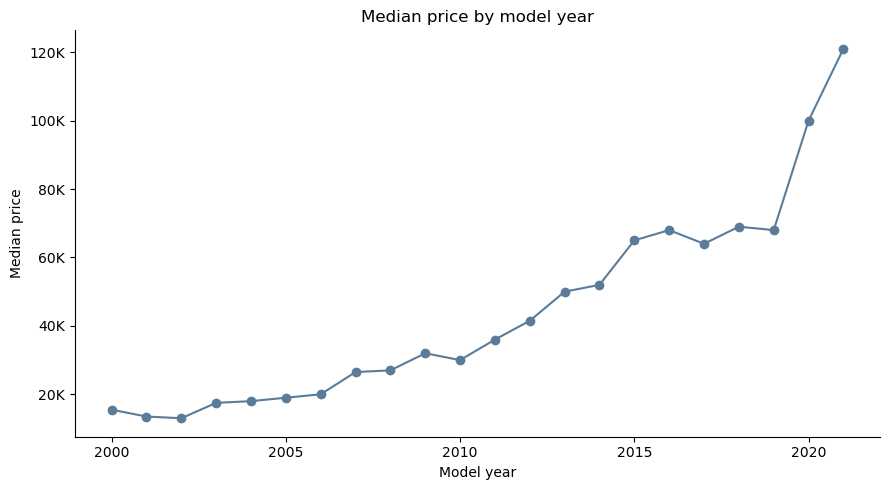

In [31]:
import matplotlib.pyplot as plt

plot_data = by_year[by_year["priced"] > 0]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(plot_data.index, plot_data["median_price"], marker="o", color="#5B7C99")
ax.set_title("Median price by model year")
ax.set_xlabel("Model year")
ax.set_ylabel("Median price")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("year_price_chart.png", dpi=150)
plt.show()

### Create a horizontal bar chart of the ten manufacturers with the most listings, highlight Toyota in a different color, and display the listing counts on the bars.

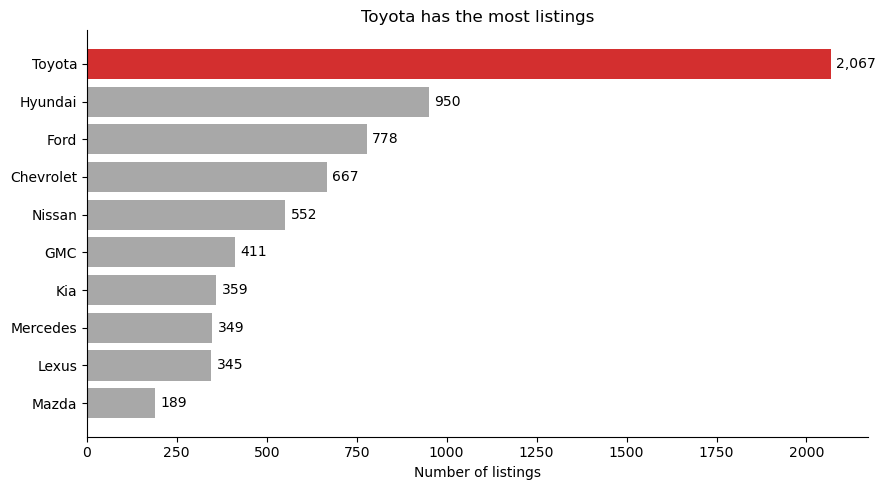

In [32]:
top10 = top.sort_values("listings")   # تصاعدي ليظهر الأكبر في الأعلى

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#D32F2F" if m == "Toyota" else "#A8A8A8" for m in top10.index]
bars = ax.barh(top10.index, top10["listings"], color=colors)
ax.bar_label(bars, fmt="{:,.0f}", padding=4)
ax.set_title("Toyota has the most listings")
ax.set_xlabel("Number of listings")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("make_listings_chart.png", dpi=150)
plt.show()

### Create a horizontal chart comparing median prices across regions that meet the requirement of at least 30 recorded prices. Highlight the region with the highest median price and save the chart.

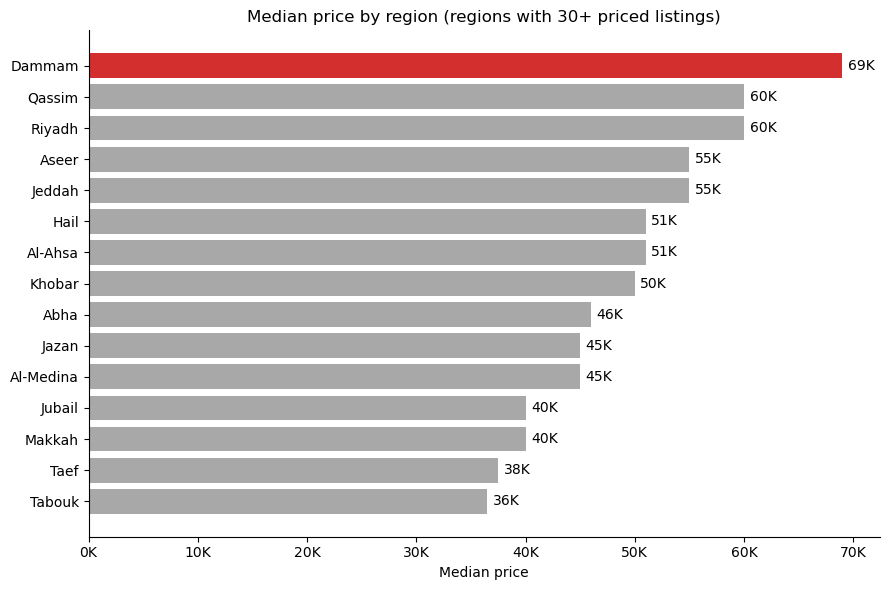

In [33]:
reg = reliable.sort_values("median_price")

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#D32F2F" if v == reg["median_price"].max() else "#A8A8A8"
          for v in reg["median_price"]]
bars = ax.barh(reg.index, reg["median_price"], color=colors)
ax.bar_label(bars, labels=[f"{v/1000:.0f}K" for v in reg["median_price"]], padding=4)
ax.set_title("Median price by region (regions with 30+ priced listings)")
ax.set_xlabel("Median price")
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K")
plt.tight_layout()
plt.savefig("region_price_chart.png", dpi=150)
plt.show()

### Create an Excel file for the car market report, prepare the summary worksheet, add the charts, and define the functions and formatting needed to write the tables.

In [34]:
from openpyxl import Workbook
from openpyxl.drawing.image import Image
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

wb = Workbook()

# ---------- ورقة Summary ----------
ws = wb.active
ws.title = "Summary"

ws["A1"] = "Used Cars Market Report"
ws["A1"].font = Font(size=18, bold=True)

priced_n = int(df["Price"].notna().sum())
ws["A2"] = (f"{len(df):,} listings analysed; {priced_n:,} "
            f"({priced_n/len(df):.0%}) have a stated price.")
ws["A3"] = "Price analysis uses priced listings only. Medians are used because expensive cars skew averages."

def add_chart(path, cell):
    img = Image(path)
    img.width, img.height = 640, 360
    ws.add_image(img, cell)

add_chart("make_listings_chart.png", "A5")
add_chart("year_price_chart.png", "A25")
add_chart("region_price_chart.png", "A45")

# ---------- دالة لكتابة جدول ----------
def write_table(sheet_name, table, index_name):
    sh = wb.create_sheet(sheet_name)
    t = table.reset_index()
    t.columns = [index_name] + list(t.columns[1:])
    header_fill = PatternFill("solid", fgColor="5B7C99")

    for c, name in enumerate(t.columns, start=1):
        cell = sh.cell(row=1, column=c, value=name)
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = header_fill
        cell.alignment = Alignment(horizontal="center")

    for r, row in enumerate(t.itertuples(index=False), start=2):
        for c, v in enumerate(row, start=1):
            if hasattr(v, "item"):          # يحوّل أرقام numpy إلى أرقام عادية
                v = v.item()
            if v != v:                      # NaN يصير خلية فاضية
                v = None
            sh.cell(row=r, column=c, value=v)

    for c in range(1, len(t.columns) + 1):
        sh.column_dimensions[get_column_letter(c)].width = 18
    sh.freeze_panes = "A2"

write_table("By Make", top, "Make")
write_table("By Year", by_year, "Year")
write_table("By Region", reliable, "Region")

# ---------- الملاحظات ----------
notes = wb.create_sheet("Notes")
lines = [
    "Data cleaning decisions",
    "1. Listings marked 'Negotiable' have no stated price and are excluded from price analysis.",
    "2. One listing with price 0 was excluded.",
    "3. Mileage above 1,000,000 km was treated as entry error (45 listings).",
    "4. Mileage under 1,000 km for cars older than 5 years (relative to 2026) was assumed to be entered in thousands of km and multiplied by 1,000 (913 listings). This is an assumption based on the value pattern.",
    "5. 20 rows identical across all columns, including the listing link, were removed as true duplicates. Listings with identical specs but different links were kept.",
    "6. Year-based analysis uses cars from 2000 onward.",
    "7. Regions with fewer than 30 priced listings are excluded from the regional chart.",
    "8. The collection date of the data is not stated; analysis uses model year.",
    "9. Findings are descriptive; they do not show causes.",
]
for i, line in enumerate(lines, start=1):
    notes.cell(row=i, column=1, value=line)
notes["A1"].font = Font(bold=True, size=14)
notes.column_dimensions["A"].width = 120

wb.save("used_cars_report.xlsx")
print("Saved used_cars_report.xlsx")

Saved used_cars_report.xlsx


### Write a standalone program named `generate_report.py` that combines data cleaning, analysis, and report generation. Include command-line options to filter results by region or manufacturer, as well as an interactive mode.

In [35]:
%%writefile generate_report.py
"""
Used Cars Market Report generator.

Usage:
    python generate_report.py
    python generate_report.py --region Riyadh
    python generate_report.py --make Toyota --region Jeddah
    python generate_report.py --interactive
"""
import argparse
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from openpyxl import Workbook
from openpyxl.drawing.image import Image
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------------- settings
# All thresholds are assumptions. Change them here and rerun.
REFERENCE_YEAR = 2026
MAX_MILEAGE_KM = 1_000_000
MIN_MILEAGE_KM = 1_000
OLD_CAR_AGE = 5
MIN_YEAR_FOR_TREND = 2000
MIN_PRICED_PER_REGION = 30
MIN_PRICED_PER_YEAR_FILTERED = 10  # used only when a filter is active
HIGHLIGHT = "#D32F2F"
MUTED = "#A8A8A8"
LINE = "#5B7C99"


# ---------------------------------------------------------------- cleaning
def load_and_clean(path):
    df = pd.read_csv(path)
    log = {"rows_raw": len(df)}

    price_text = df["Price"].astype(str).str.replace(",", "", regex=False)
    df["Price"] = pd.to_numeric(price_text, errors="coerce")
    log["price_missing_text"] = int(df["Price"].isna().sum())

    zero = df["Price"] == 0
    log["price_zero"] = int(zero.sum())
    df.loc[zero, "Price"] = pd.NA
    df["Price"] = df["Price"].astype(float)

    too_high = df["Mileage"] > MAX_MILEAGE_KM
    log["mileage_too_high"] = int(too_high.sum())
    df.loc[too_high, "Mileage"] = pd.NA

    df["Age"] = REFERENCE_YEAR - df["Year"]
    suspicious = (df["Mileage"] < MIN_MILEAGE_KM) & (df["Age"] > OLD_CAR_AGE)
    log["mileage_suspicious"] = int(suspicious.sum())
    df["Mileage_adjusted"] = suspicious
    df.loc[suspicious, "Mileage"] = df.loc[suspicious, "Mileage"] * 1000

    
    before = len(df)
    df = df.drop_duplicates()
    df = df.drop(columns=["Link"], errors="ignore")
    log["duplicates_removed"] = before - len(df)
    log["rows_clean"] = len(df)
    log["rows_priced"] = int(df["Price"].notna().sum())
    return df, log


# ---------------------------------------------------------------- filtering
def _match(series, value):
    return series.astype(str).str.strip().str.lower() == value.strip().lower()


def apply_filters(df, region=None, make=None):
    """Return (filtered_df, folder_label, readable_text)."""
    label_parts, text_parts = [], []
    if region:
        mask = _match(df["Region"], region)
        if not mask.any():
            options = ", ".join(df["Region"].value_counts().index[:15])
            raise SystemExit(f"Region '{region}' not found. Examples: {options}")
        df = df[mask]
        region = df["Region"].iloc[0]
        label_parts.append(f"region_{region}")
        text_parts.append(f"region = {region}")
    if make:
        mask = _match(df["Make"], make)
        if not mask.any():
            options = ", ".join(df["Make"].value_counts().index[:15])
            raise SystemExit(f"Make '{make}' not found"
                             f"{' in this region' if region else ''}. Examples: {options}")
        df = df[mask]
        make = df["Make"].iloc[0]
        label_parts.append(f"make_{make}")
        text_parts.append(f"make = {make}")
    label = "_".join(label_parts).replace(" ", "-")
    return df, label, ", ".join(text_parts)


def ask_user(df):
    print("\nPress Enter to skip a question (= all).")
    print("Regions with most listings:", ", ".join(df["Region"].value_counts().index[:10]))
    region = input("Region: ").strip() or None
    print("Makes with most listings:", ", ".join(df["Make"].value_counts().index[:10]))
    make = input("Make: ").strip() or None
    return region, make


# ---------------------------------------------------------------- analysis
def analyse(df, min_year_priced=1):
    by_make = (df.groupby("Make")
                 .agg(listings=("Make", "size"),
                      priced=("Price", "count"),
                      median_price=("Price", "median"))
                 .sort_values("listings", ascending=False)
                 .head(10))

    modern = df[df["Year"] >= MIN_YEAR_FOR_TREND]
    by_year = (modern.groupby("Year")
                     .agg(priced=("Price", "count"),
                          median_price=("Price", "median")))
    by_year = by_year[by_year["priced"] >= min_year_priced]

    by_region = (df.groupby("Region")
                   .agg(listings=("Region", "size"),
                        priced=("Price", "count"),
                        median_price=("Price", "median")))
    reliable = (by_region[by_region["priced"] >= MIN_PRICED_PER_REGION]
                .sort_values("median_price", ascending=False))
    return by_make, by_year, reliable


# ---------------------------------------------------------------- charts
def _style(ax):
    ax.spines[["top", "right"]].set_visible(False)


def make_charts(by_make, by_year, reliable, out, skip_make=False, skip_region=False):
    paths = {}

    if not skip_make and len(by_make):
        top10 = by_make.sort_values("listings")
        leader = by_make["listings"].idxmax()
        fig, ax = plt.subplots(figsize=(9, 5))
        colors = [HIGHLIGHT if m == leader else MUTED for m in top10.index]
        bars = ax.barh(top10.index, top10["listings"], color=colors)
        ax.bar_label(bars, fmt="{:,.0f}", padding=4)
        ax.set_title(f"{leader} has the most listings")
        ax.set_xlabel("Number of listings (all, including unpriced)")
        _style(ax)
        plt.tight_layout()
        paths["make"] = out / "make_listings_chart.png"
        plt.savefig(paths["make"], dpi=150)
        plt.close(fig)

    data = by_year[by_year["priced"] > 0]
    if len(data) >= 2:
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(data.index, data["median_price"], marker="o", color=LINE)
        ax.set_title("Median price by model year")
        ax.set_xlabel("Model year")
        ax.set_ylabel("Median price")
        ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K")
        _style(ax)
        plt.tight_layout()
        paths["year"] = out / "year_price_chart.png"
        plt.savefig(paths["year"], dpi=150)
        plt.close(fig)

    reg = reliable.sort_values("median_price")
    if len(reg) and not skip_region:
        top_value = reg["median_price"].max()
        fig, ax = plt.subplots(figsize=(9, 6))
        colors = [HIGHLIGHT if v == top_value else MUTED
                  for v in reg["median_price"]]
        bars = ax.barh(reg.index, reg["median_price"], color=colors)
        ax.bar_label(bars,
                     labels=[f"{v/1000:.0f}K" for v in reg["median_price"]],
                     padding=4)
        ax.set_title(f"Median price by region "
                     f"(regions with {MIN_PRICED_PER_REGION}+ priced listings)")
        ax.set_xlabel("Median price")
        ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K")
        _style(ax)
        plt.tight_layout()
        paths["region"] = out / "region_price_chart.png"
        plt.savefig(paths["region"], dpi=150)
        plt.close(fig)
    return paths


# ---------------------------------------------------------------- Excel
def write_table(wb, sheet_name, table, index_name):
    sh = wb.create_sheet(sheet_name)
    t = table.reset_index()
    t.columns = [index_name] + list(t.columns[1:])
    fill = PatternFill("solid", fgColor="5B7C99")

    for c, name in enumerate(t.columns, start=1):
        cell = sh.cell(row=1, column=c, value=name)
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = fill
        cell.alignment = Alignment(horizontal="center")

    for r, row in enumerate(t.itertuples(index=False), start=2):
        for c, v in enumerate(row, start=1):
            if hasattr(v, "item"):
                v = v.item()
            if v != v:
                v = None
            sh.cell(row=r, column=c, value=v)

    for c in range(1, len(t.columns) + 1):
        sh.column_dimensions[get_column_letter(c)].width = 18
    sh.freeze_panes = "A2"


def write_report(path, log, by_make, by_year, reliable, charts, n_rows, n_priced, filter_text=None):
    wb = Workbook()
    ws = wb.active
    ws.title = "Summary"
    ws["A1"] = "Used Cars Market Report"
    ws["A1"].font = Font(size=18, bold=True)
    pct = f"{n_priced / n_rows:.0%}" if n_rows else "n/a"
    ws["A2"] = f"{n_rows:,} listings analysed; {n_priced:,} ({pct}) have a stated price."
    ws["A3"] = ("Price analysis uses priced listings only. Medians are used "
                "because expensive cars skew averages.")
    if filter_text:
        ws["A4"] = f"Filter applied: {filter_text}"
        ws["A4"].font = Font(bold=True)

    row = 6
    for key in ("make", "year", "region"):
        if key in charts:
            img = Image(str(charts[key]))
            img.width, img.height = 640, 360
            ws.add_image(img, f"A{row}")
            row += 20

    if len(by_make) > 1:
        write_table(wb, "By Make", by_make, "Make")
    write_table(wb, "By Year", by_year, "Year")
    if len(reliable) > 1:
        write_table(wb, "By Region", reliable, "Region")

    notes = wb.create_sheet("Notes")
    lines = [
        "Data cleaning decisions",
        f"1. {log['price_missing_text']:,} listings had no numeric price "
        "(marked 'Negotiable') and are excluded from price analysis.",
        f"2. {log['price_zero']} listing(s) with price 0 were excluded.",
        f"3. Mileage above {MAX_MILEAGE_KM:,} km was treated as an entry error "
        f"({log['mileage_too_high']} listings); the rest of each row was kept.",
        f"4. Mileage under {MIN_MILEAGE_KM:,} km for cars older than {OLD_CAR_AGE} "
        f"years (relative to {REFERENCE_YEAR}) was assumed to be entered in thousands "
        f"of km and multiplied by 1,000 ({log['mileage_suspicious']} listings). "
        f"This is an assumption based on the value pattern.",
        f"5. {log['duplicates_removed']} rows identical across all columns, "
        "including the listing link, were removed as true duplicates. "
        "Listings with identical specs but different links were kept.",
        f"6. Year-based analysis uses cars from {MIN_YEAR_FOR_TREND} onward.",
        f"7. Regions with fewer than {MIN_PRICED_PER_REGION} priced listings "
        "are excluded from the regional chart.",
        "8. The collection date of the data is not stated; analysis uses model year.",
        "9. Findings are descriptive; they do not show causes.",
    ]
    if filter_text:
        lines.append(f"10. Report filtered by {filter_text}. Cleaning statistics above "
                     "describe the full dataset. Years with fewer than "
                     f"{MIN_PRICED_PER_YEAR_FILTERED} priced listings are left out of the year table and chart.")
    for i, line in enumerate(lines, start=1):
        notes.cell(row=i, column=1, value=line)
    notes["A1"].font = Font(bold=True, size=14)
    notes.column_dimensions["A"].width = 120

    wb.save(path)


# ---------------------------------------------------------------- main
def main():
    parser = argparse.ArgumentParser(description="Generate the used cars report.")
    parser.add_argument("--input", default="UsedCarsSA_Unclean_EN.csv")
    parser.add_argument("--output", default="output")
    parser.add_argument("--region", help="report only this region, e.g. Riyadh")
    parser.add_argument("--make", help="report only this make, e.g. Toyota")
    parser.add_argument("--interactive", action="store_true",
                        help="ask which region and make to report on")
    args = parser.parse_args()

    df, log = load_and_clean(args.input)
    print("Cleaning summary (full dataset):")
    for k, v in log.items():
        print(f"  {k}: {v:,}")

    region, make = args.region, args.make
    if args.interactive:
        region, make = ask_user(df)

    df, label, filter_text = apply_filters(df, region, make)
    filtered = bool(label)
    if filtered:
        print(f"\nFilter: {filter_text} -> {len(df):,} listings, "
              f"{int(df['Price'].notna().sum()):,} priced")

    out = Path(args.output) / label if filtered else Path(args.output)
    out.mkdir(parents=True, exist_ok=True)

    by_make, by_year, reliable = analyse(
        df, MIN_PRICED_PER_YEAR_FILTERED if filtered else 1)
    charts = make_charts(by_make, by_year, reliable, out,
                         skip_make=bool(make), skip_region=bool(region))

    df.to_csv(out / "used_cars_clean.csv", index=False)
    report = out / "used_cars_report.xlsx"
    write_report(report, log, by_make, by_year, reliable, charts,
                 n_rows=len(df), n_priced=int(df["Price"].notna().sum()),
                 filter_text=filter_text)
    print(f"Saved {report}")


if __name__ == "__main__":
    main()

Overwriting generate_report.py


### Run the report program for the Riyadh region to generate a report focused on car listings in that region.

In [36]:
%run generate_report.py --region Riyadh

Cleaning summary (full dataset):
  rows_raw: 8,248
  price_missing_text: 2,596
  price_zero: 1
  mileage_too_high: 45
  mileage_suspicious: 913
  duplicates_removed: 20
  rows_clean: 8,228
  rows_priced: 5,635

Filter: region = Riyadh -> 3,300 listings, 2,350 priced
Saved output\region_Riyadh\used_cars_report.xlsx


### Run the report program without filters to generate an overall report using the full dataset.

In [37]:
%run generate_report.py

Cleaning summary (full dataset):
  rows_raw: 8,248
  price_missing_text: 2,596
  price_zero: 1
  mileage_too_high: 45
  mileage_suspicious: 913
  duplicates_removed: 20
  rows_clean: 8,228
  rows_priced: 5,635
Saved output\used_cars_report.xlsx


### Create a `.gitignore` file to specify files and folders that Git should ignore, such as CSV files, the output folder, and temporary files.

In [38]:
%%writefile .gitignore
.ipynb_checkpoints/
~$*
*.csv
output/

Writing .gitignore
